# Epsilon-schedule experiments - HonourGod

My part of the sweep varies the exploration schedule only: the starting
epsilon, the final epsilon and how many steps the decay takes. Every other
hyperparameter is held at the group baseline (lr 1e-4, gamma 0.99, batch 32,
400,000 steps, buffer 50,000), so any difference in the results comes from
exploration and nothing else.

The runs themselves were done by `run_all.py` on a local RTX 3060, not in
this notebook. A sweep of ten 400k-step runs takes about eight hours, which
needs a process that survives a closed laptop - a notebook kernel does not.
This notebook is the analysis of the logs those runs produced.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Works whether the notebook is run from its own folder or the repo root.
RUNS = Path.cwd()
if not (RUNS / 'summary.csv').exists():
    RUNS = Path('experiments/HonourGod')

# model.pth is only written once a run reaches its last step, so this
# skips anything still training.
runs = sorted(p.name for p in RUNS.glob('exp*') if (p / 'model.pth').exists())
print(f'{len(runs)} finished runs:', ', '.join(runs))


10 finished runs: exp01, exp02, exp03, exp04, exp05, exp06, exp07, exp08, exp09, exp10


## The configurations

Experiments 1 to 4 change the decay length, 5 to 7 change the floor, 8 and 9
change the starting value. Experiment 10 combines my best schedule with
Alliane's best batch size.


In [2]:
config = pd.DataFrame(
    [('exp01', 1.0, 0.01, 200_000, 32, 'baseline'),
     ('exp02', 1.0, 0.01, 50_000, 32, 'fast decay'),
     ('exp03', 1.0, 0.01, 20_000, 32, 'very fast decay'),
     ('exp04', 1.0, 0.01, 350_000, 32, 'slow decay'),
     ('exp05', 1.0, 0.10, 200_000, 32, 'floor 0.10'),
     ('exp06', 1.0, 0.20, 200_000, 32, 'floor 0.20'),
     ('exp07', 1.0, 0.001, 200_000, 32, 'floor 0.001'),
     ('exp08', 0.5, 0.01, 200_000, 32, 'low start'),
     ('exp09', 0.1, 0.01, 200_000, 32, 'almost greedy start'),
     ('exp10', 1.0, 0.01, 20_000, 128, 'best schedule + batch 128')],
    columns=['run', 'eps_start', 'eps_end', 'eps_decay', 'batch', 'tests'],
).set_index('run')
config


,eps_start,eps_end,eps_decay,batch,tests
run,,,,,
exp01,1.0,0.010,200000,32,baseline
exp02,1.0,0.010,50000,32,fast decay
exp03,1.0,0.010,20000,32,very fast decay
exp04,1.0,0.010,350000,32,slow decay
exp05,1.0,0.100,200000,32,floor 0.10
exp06,1.0,0.200,200000,32,floor 0.20
exp07,1.0,0.001,200000,32,floor 0.001
exp08,0.5,0.010,200000,32,low start
exp09,0.1,0.010,200000,32,almost greedy start


## Summary of what each run achieved

`crossed_-20` is the step where the 100-episode average first rose above
-20. Random play on Pong scores about -21, so it marks the point a run
started doing better than random. Episode length matters too: a longer game
means the agent is returning the ball rather than missing immediately.


In [3]:
def describe(name):
    log = pd.read_csv(RUNS / name / 'log.csv')
    mean100 = log['reward'].rolling(100, min_periods=1).mean()

    # Only count the crossing once a full 100-episode window exists.
    above = log['step'][(mean100 > -20) & (log.index >= 99)]
    crossed = int(above.iloc[0]) if len(above) else None

    return {
        'episodes': len(log),
        'first_100': round(log['reward'].head(100).mean(), 2),
        'final_100': round(log['reward'].tail(100).mean(), 2),
        'best_game': int(log['reward'].max()),
        'crossed_-20': crossed,
        'len_first_50': int(log['length'].head(50).mean()),
        'len_last_50': int(log['length'].tail(50).mean()),
        'loss_median': round(log['loss'].median(), 4),
    }


summary = pd.DataFrame({r: describe(r) for r in runs}).T
summary = config.join(summary, how='right')
summary.sort_values('final_100', ascending=False)


,eps_start,eps_end,eps_decay,batch,tests,episodes,first_100,final_100,best_game,crossed_-20,len_first_50,len_last_50,loss_median
exp10,1.0,0.010,20000,128,best schedule + batch 128,200.0,-20.42,-14.39,8.0,135805.0,888.0,3951.0,0.0053
exp03,1.0,0.010,20000,32,very fast decay,306.0,-20.67,-16.30,-8.0,169683.0,833.0,2171.0,0.0046
exp07,1.0,0.001,200000,32,floor 0.001,342.0,-20.51,-17.41,-9.0,236226.0,882.0,2077.0,0.0051
exp08,0.5,0.010,200000,32,low start,304.0,-20.44,-17.46,-8.0,202455.0,865.0,2360.0,0.0052
exp05,1.0,0.100,200000,32,floor 0.10,356.0,-20.45,-17.99,-13.0,273191.0,902.0,1641.0,0.0060
exp09,0.1,0.010,200000,32,almost greedy start,344.0,-20.64,-18.32,-10.0,251582.0,845.0,1937.0,0.0048
exp06,1.0,0.200,200000,32,floor 0.20,371.0,-20.39,-19.02,-14.0,282388.0,892.0,1552.0,0.0055
exp01,1.0,0.010,200000,32,baseline,363.0,-20.32,-19.36,-14.0,329245.0,918.0,1779.0,0.0053
exp04,1.0,0.010,350000,32,slow decay,366.0,-20.44,-19.41,-14.0,346665.0,927.0,1802.0,0.0057
exp02,1.0,0.010,50000,32,fast decay,503.0,-20.74,-20.87,-18.0,NaN,851.0,784.0,0.0300


## All runs on one axis

The 100-episode average against the step count. The spread between the best
run and the failed one is about 6 points of score.

Three runs are picked out: experiment 10 (best model), experiment 3 (best
epsilon schedule on its own) and experiment 2 (the collapse).


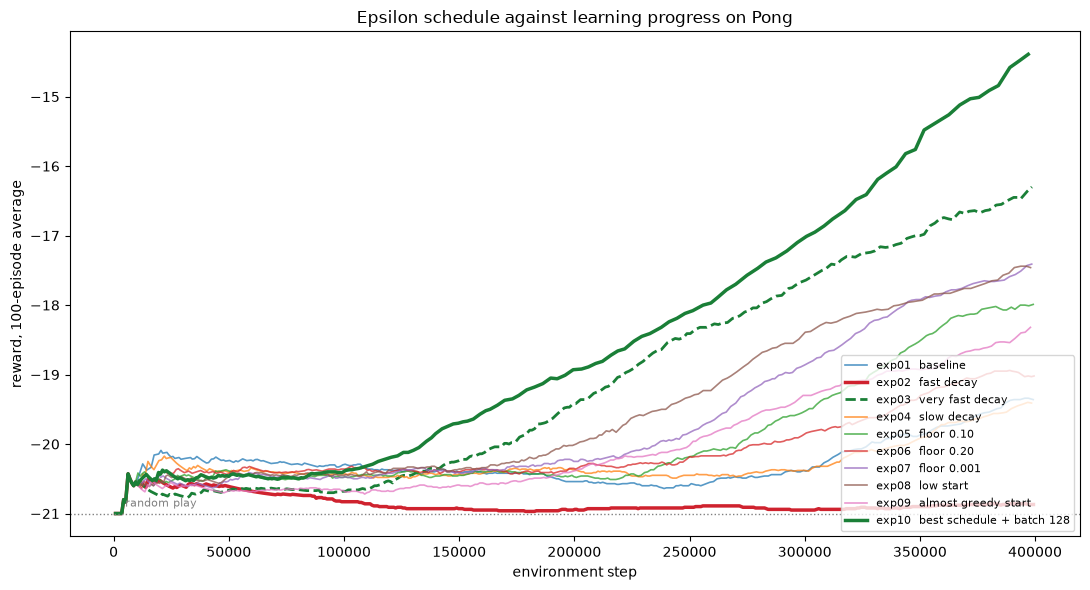

In [4]:
fig, ax = plt.subplots(figsize=(11, 6))

# Pick out the best model, the best schedule and the failed run.
highlight = {'exp10': dict(lw=2.5, color='#1a7f37'),
             'exp03': dict(lw=2.0, color='#1a7f37', ls='--'),
             'exp02': dict(lw=2.5, color='#cf222e')}

for name in runs:
    log = pd.read_csv(RUNS / name / 'log.csv')
    mean100 = log['reward'].rolling(100, min_periods=1).mean()
    style = highlight.get(name, dict(lw=1.2, alpha=0.75))
    ax.plot(log['step'], mean100,
            label=f"{name}  {config.loc[name, 'tests']}", **style)

ax.axhline(-21, ls=':', c='grey', lw=1)
ax.annotate('random play', (5000, -20.9), fontsize=8, color='grey')
ax.set_xlabel('environment step')
ax.set_ylabel('reward, 100-episode average')
ax.set_title('Epsilon schedule against learning progress on Pong')
ax.legend(fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()


## Why experiment 2 failed

Experiment 2 is the only run that ended worse than it started. The reward
curve alone just looks flat; the loss column shows what actually happened.

With a batch of 32, a network that outputs the same Q-value for every state
misses each +1 or -1 reward by exactly 1, so its mean squared error lands on
a multiple of 1/32 = 0.03125. A healthy run's loss moves around between
quarters; a collapsed run's loss sits on those marks and stays there.


In [5]:
marks = [0, 1 / 32, 2 / 32, 3 / 32]

for name in ['exp02', 'exp03']:
    log = pd.read_csv(RUNS / name / 'log.csv')

    q = len(log) // 4
    quarters = [round(float(log['loss'].iloc[i * q:(i + 1) * q].median()), 4)
                for i in range(4)]

    after_q1 = log['loss'].iloc[q:]
    on_mark = sum(any(abs(v - m) < 0.004 for m in marks) for v in after_q1)

    print(f'{name}: loss median per quarter {quarters}')
    print(f'{name}: {100 * on_mark / len(after_q1):.0f}% of losses sit '
          f'on a multiple of 1/32')
    print()


exp02: loss median per quarter [0.0291, 0.0303, 0.0298, 0.0304]
exp02: 93% of losses sit on a multiple of 1/32

exp03: loss median per quarter [0.0037, 0.0035, 0.0056, 0.0054]
exp03: 40% of losses sit on a multiple of 1/32



## Findings

**Shorter exploration won, consistently.** The step at which a run crossed
-20 predicts where it finished, almost in rank order. Every change that cut
exploration short - a faster decay, a lower floor, a lower start - beat the
200,000-step baseline, and the slowest schedule (experiment 4, decaying over
350,000 of 400,000 steps) was the worst of the successful runs. At this
budget the limit is not how much the agent explores but how much of the run
is left to learn in afterwards.

**The schedule gain compounds with a larger batch.** Experiment 10 pairs the
20,000-step decay with Alliane's best batch size of 128. It crossed -20 at
136k steps, finished at -14.39 and won a game outright (+8), with games of
nearly 4,000 steps. Two hyperparameters change at once there, so it cannot
attribute the gain on its own - but it does show the two findings add rather
than cancel.

**A better training average is not a more reliable policy.** Played greedily
through `play.py` over ten fixed seeds, experiment 10 averaged -11.20 but
ranged from -1 to -20, while Alliane's experiment 9 averaged -10.10 within a
narrower -6 to -13. The averages are within each other's error, so the group
shipped her steadier model as `dqn_model.pth` for the live demonstration.
The final 100 training episodes still include the 1% exploration floor and
are a noisy estimate of greedy behaviour.

**A high floor is the one clear harm.** Keeping epsilon at 0.20 (experiment
6) gave the shortest final games of any successful run. One action in five
being random keeps throwing away points the learned policy would have saved.
A floor of 0.001 (experiment 7) showed no downside at all over 400k steps.

**A fully random start is not needed.** Experiments 8 and 9 cut the starting
epsilon to 0.5 and 0.1 and both beat the baseline. The 10,000-step random
warmup already fills the buffer before learning begins, and an untrained
network's greedy actions are close to arbitrary in any case.

**What this data cannot settle.** Experiment 2 collapsed, yet experiment 3
decays faster still and was the best run in the sweep - so the decay length
alone cannot explain the collapse. Each configuration was run once, and
`train.py` seeds only the environment, not the network initialisation or the
replay sampling, so an unlucky initialisation is just as plausible.
Separating the two needs several seeds per configuration, which did not fit
the compute budget. The collapse mechanism is certain; its trigger is not.
Gaps of less than half a point, such as experiments 7 and 8, should be read
as ties.
